<a href="https://colab.research.google.com/github/fitraadhim/244107020089_MachineLearning/blob/main/JS04/tugasJS04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_csv('Mall_Customers.csv')
display(df.head())
df.info()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [2]:
# Kita pilih fitur 'Annual Income (k$)' dan 'Spending Score (1-100)'
# karena sangat representatif untuk segmentasi pelanggan mall.
X_kmeans = df[['Annual Income (k$)', 'Spending Score (1-100)']]

display(X_kmeans.head())

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


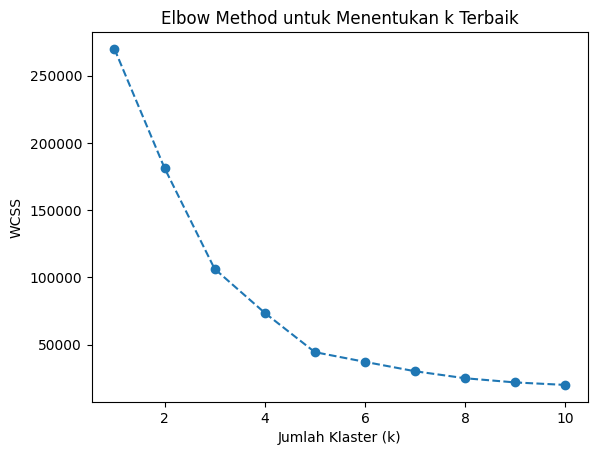

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_kmeans)
    wcss.append(kmeans.inertia_)

# Plot Elbow Method
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method untuk Menentukan k Terbaik')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('WCSS')
plt.show()

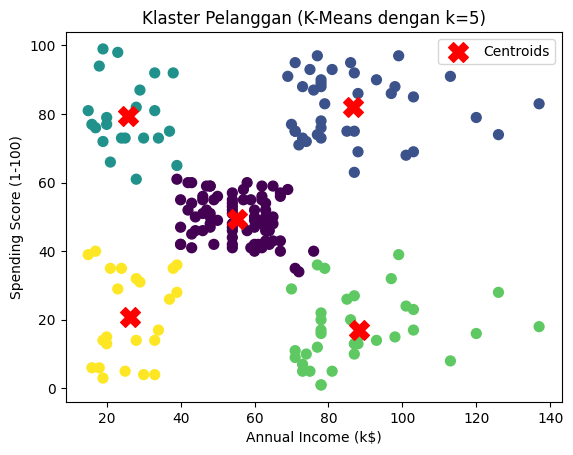

In [4]:
# Berdasarkan metode elbow, titik siku (optimum) biasanya berada di k = 5
kmeans = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
y_kmeans = kmeans.fit_predict(X_kmeans)

# Visualisasi hasil klasterisasi K-Means
plt.scatter(X_kmeans.values[:, 0], X_kmeans.values[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], s=200, c='red', marker='X', label='Centroids')
plt.title('Klaster Pelanggan (K-Means dengan k=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

In [5]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

# 1. Buat dataset make_moons (1000 sampel, noise=0.05)
X_moons, labels_true = make_moons(n_samples=1000, noise=0.05, random_state=42)

# 2. Normalisasi / Standarisasi data
X_moons_scaled = StandardScaler().fit_transform(X_moons)

In [6]:
import numpy as np
from sklearn import metrics
from sklearn.cluster import DBSCAN

# Menjalankan DBSCAN sesuai ketentuan
db_moons = DBSCAN(eps=0.2, min_samples=5).fit(X_moons_scaled)
labels_moons = db_moons.labels_

# Menghitung jumlah klaster & noise (mengabaikan -1 sebagai noise)
n_clusters_moons = len(set(labels_moons)) - (1 if -1 in labels_moons else 0)
n_noise_moons = list(labels_moons).count(-1)

print(f"Estimated number of clusters: {n_clusters_moons}")
print(f"Estimated number of noise points: {n_noise_moons}")

Estimated number of clusters: 2
Estimated number of noise points: 0


In [7]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels_moons):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels_moons):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels_moons):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels_moons):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels_moons):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X_moons_scaled, labels_moons):.3f}")

Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index: 1.000
Adjusted Mutual Information: 1.000
Silhouette Coefficient: 0.391


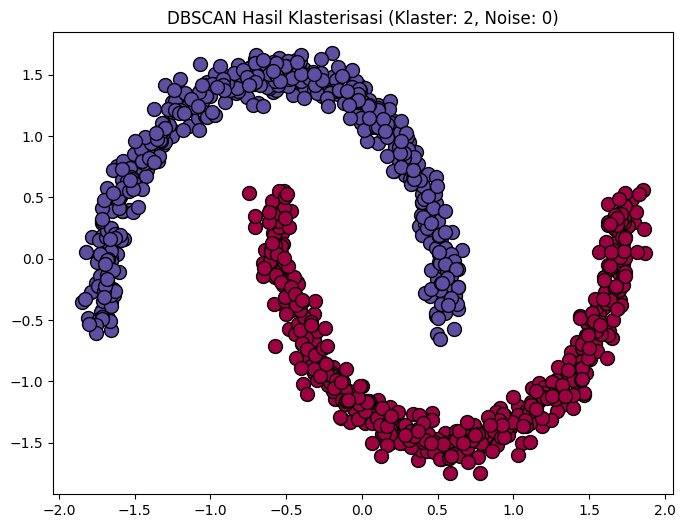

In [8]:
unique_labels = set(labels_moons)
core_samples_mask = np.zeros_like(labels_moons, dtype=bool)
core_samples_mask[db_moons.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(8, 6))
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Warna hitam untuk noise

    class_member_mask = (labels_moons == k)

    # Core samples (titik besar)
    xy = X_moons_scaled[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col), markeredgecolor='k', markersize=10)

    # Non-core samples (titik kecil)
    xy = X_moons_scaled[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col), markeredgecolor='k', markersize=4)

plt.title(f'DBSCAN Hasil Klasterisasi (Klaster: {n_clusters_moons}, Noise: {n_noise_moons})')
plt.show()

In [9]:
eps_values = [0.05, 0.1, 0.3, 0.5]
min_samples_values = [3, 10, 20]

for e in eps_values:
    for ms in min_samples_values:
        db_exp = DBSCAN(eps=e, min_samples=ms).fit(X_moons_scaled)
        lbls = db_exp.labels_
        n_cl = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_ns = list(lbls).count(-1)
        print(f"eps={e}, min_samples={ms} --> Klaster: {n_cl}, Noise: {n_ns}")

eps=0.05, min_samples=3 --> Klaster: 69, Noise: 186
eps=0.05, min_samples=10 --> Klaster: 3, Noise: 970
eps=0.05, min_samples=20 --> Klaster: 0, Noise: 1000
eps=0.1, min_samples=3 --> Klaster: 2, Noise: 14
eps=0.1, min_samples=10 --> Klaster: 7, Noise: 57
eps=0.1, min_samples=20 --> Klaster: 6, Noise: 850
eps=0.3, min_samples=3 --> Klaster: 2, Noise: 0
eps=0.3, min_samples=10 --> Klaster: 2, Noise: 0
eps=0.3, min_samples=20 --> Klaster: 2, Noise: 0
eps=0.5, min_samples=3 --> Klaster: 2, Noise: 0
eps=0.5, min_samples=10 --> Klaster: 2, Noise: 0
eps=0.5, min_samples=20 --> Klaster: 2, Noise: 0
